# **Project Overview & Methodology**
## Alberta Wind Energy Site Selection & Probabilistic Risk Forecasting
---
### 1. Introduction and Background

When energy companies build wind farms, choosing the wrong location or failing to anticipate weather changes can cost millions of dollars and destabilize the power grid.

This project uses python based data analysis focused on Alberta to solve two core problems

1. **Finding the Best Location**: Using weather data to pinpoint areas where the wind is both strong and consistent (avoiding erratic/turbulent zones)
2. **Predicting Power & Risk**: Running computer simulations to forecast how much electricity a wind farm will produce tomorrow

---
### **Methodology**
This project is built using four main phases:

**Step 1: Spatiotemporal Data Collection**
We pull historical hourly weather records across a grid of key locations in alberta using Open-Meteo Historical Archive API and organize the data into a clean, unified Pandas DataFrame indexed by time and location.

**Step 2: Spatial Variance and Consistensy Analysis**
Computing long-term temporal means($\mu$) to quantify resource magnitude and standard deviations($\sigma$) or rolling gradients ($\frac{dV}{dt}$) to evaluate atmospheric turbulence

Using these the project will identify optimal geographical zones characterized by high mean wind velocities and low temporal variance, ensuring laminar predictable airflow that minimizes mechanical fatigue on turbine infrastructure

**Step 3: Stochastic Modeling & Monte Carlo Simulation**
Because windspeeds exhibit non-negative, right-skewed behaviour, velocities are modeled using the two parameter weibull distribution

$$\text{PDF}(v; A, k) = \left(\frac{k}{A}\right) \left(\frac{v}{A}\right)^{k-1} \exp\left[-\left(\frac{v}{A}\right)^k\right]$$

Where $A$ represents the scale parameter (wind magnitude) and $k$ represents the shape parameter (consistency index)

Utilizing inverse transform sampling with uniform random variables to execute thousands of Monte Carlo simulation runs, generating probabilistic synthetic weather profiles that account for atmospheric uncertainty.

**Step 4: Aerodynamic Conversion & Risk Profiling**
Power curve modelling by passing simulated wind velocity vectors $v$ through a piecewise turbine power curve function. Instead of guessing a single number, the model produces P10(pessimistic), P50(expected), and P90(optimistic) confidence envelopes. This givese energy operators a clear risk range to plan their grid schedules safely.





### **Step 1: Libraries and Spatiotemporal Data**

In [24]:
import pandas as pd
import requests
from datetime import datetime
import numpy as np
import folium
from folium.plugins import HeatMap
from scipy.interpolate import griddata
import matplotlib.pyplot as plt


print("Libraries imported successfully.")

Libraries imported successfully.


### **Generating grid**

In [11]:
# Defining Alberta's geographic bounding box and creating a grid
# Alberta spans roughly Lat: 49 degrees N to 60 degrees N, long: -120W to -110W

latPoints = np.linspace(49.5,59.5,15)
longPoints = np.linspace(-119.5,-110.5,15)

provincialGrid = {}
gridId = 1
for lat in latPoints:
    for long in longPoints:
        provincialGrid[f"Site_{gridId}"] = {"Latitude": round(lat, 4), "Longitude": round(long, 4)}
        gridId += 1

print(f" Generated {len(provincialGrid)} grid points for Alberta.")


 Generated 225 grid points for Alberta.


### Setting Historical date range and looping through provincial grid and pulling hourly data from Open Meteo:

In [16]:
# Setting historical date range for full year of 2024
startDate = datetime(2024, 1, 1)
endDate = datetime(2024, 12, 31)

allLocationData = []
total_sites = len(provincialGrid)
print(f"Fetching wind data for the year {startDate.year} across {total_sites} sites...\n")

# Loop through with an index counter (starting at 1)
for idx, (name, coords) in enumerate(provincialGrid.items(), start=1):
    print(f"[{idx}/{total_sites}] Fetching data for {name} (Lat: {coords['Latitude']}, Lon: {coords['Longitude']})...", end="\r")
    
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": coords["Latitude"],
        "longitude": coords["Longitude"],
        "start_date": startDate.strftime("%Y-%m-%d"),
        "end_date": endDate.strftime("%Y-%m-%d"),
        "hourly": ["wind_speed_10m"]
    }

    response = requests.get(url, params=params)
    if response.status_code == 200:
        data = response.json()
        hourly = data["hourly"]

        dfLoc = pd.DataFrame({
            "timestamp": pd.to_datetime(hourly["time"]),
            "location": name,
            "latitude": coords["Latitude"],
            "longitude": coords["Longitude"],
            "wind_speed_10m": hourly["wind_speed_10m"]
        })
        allLocationData.append(dfLoc)
    else:
        print(f"\nFailed for {name}: Status code {response.status_code}")

print("\nAll site data fetched successfully!")
masterWeatherDF = pd.concat(allLocationData, ignore_index=True)

Fetching wind data for the year 2024 across 225 sites...

[225/225] Fetching data for Site_225 (Lat: 59.5, Lon: -110.5).........
All site data fetched successfully!


### Calculating Windspeed Per site and creating contour map of windspeeds


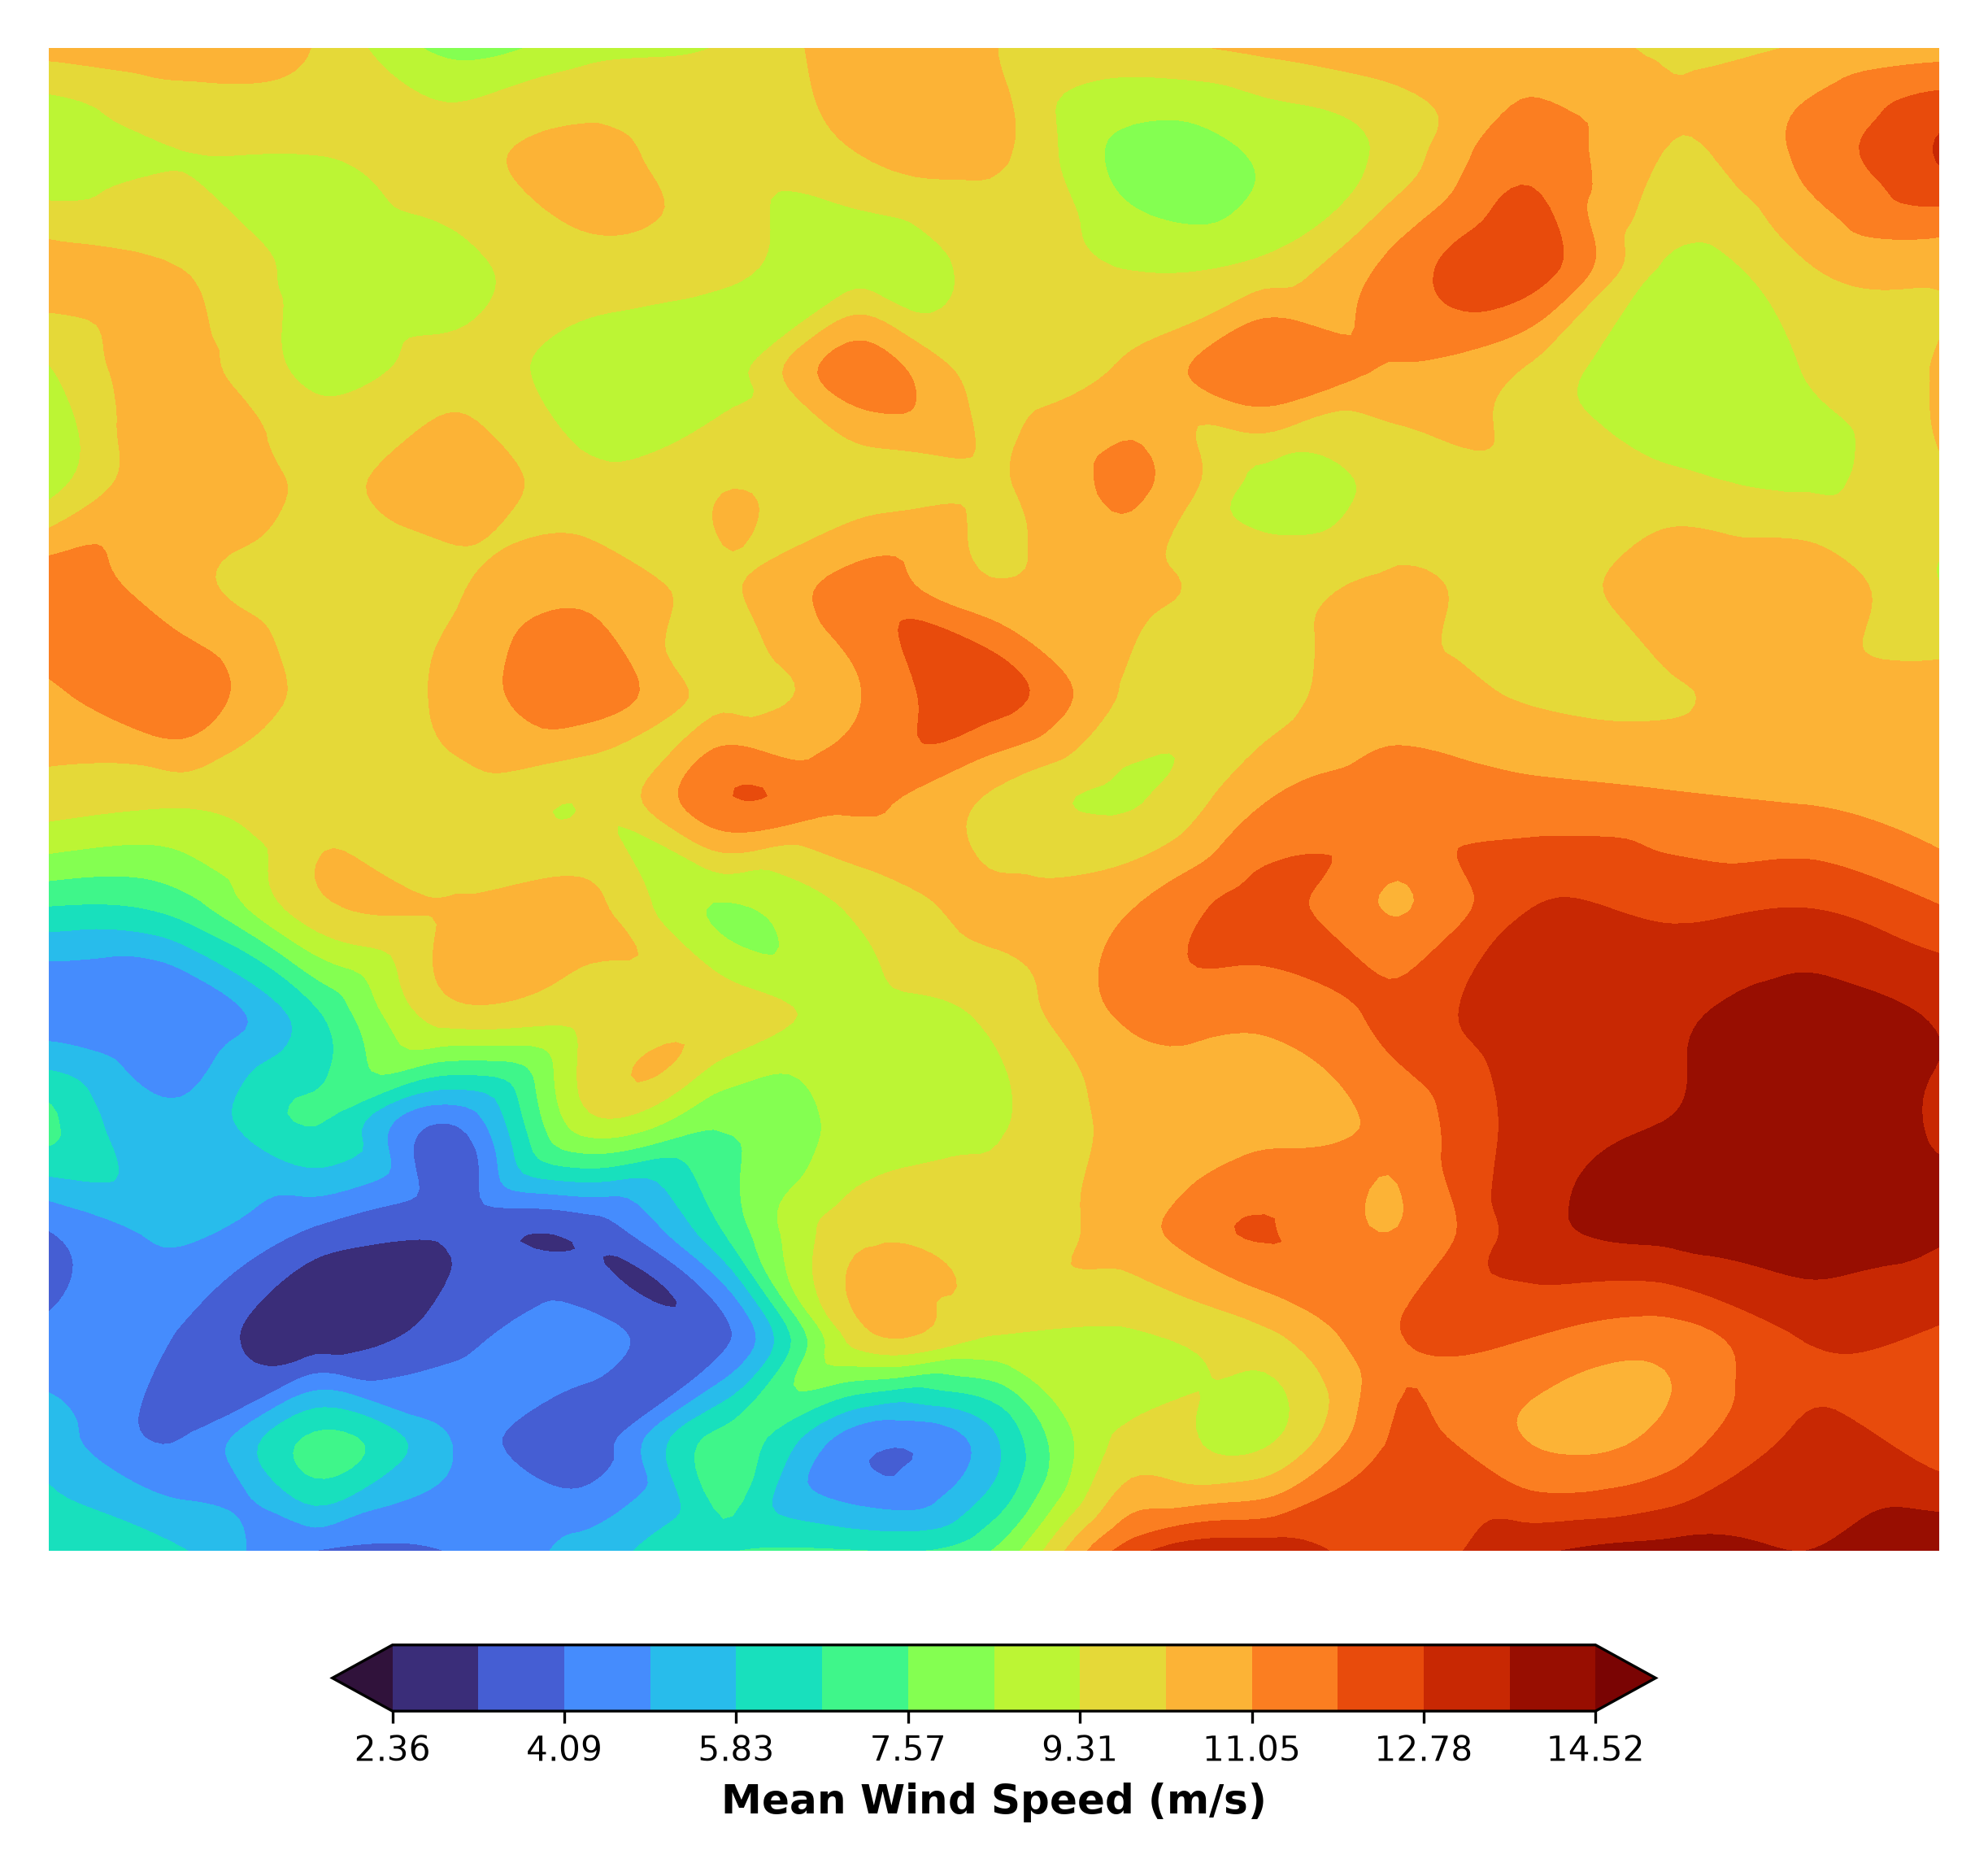

In [28]:
# 1. Group data and extract points/values
siteMeans = masterWeatherDF.groupby(["location", "latitude", "longitude"])["wind_speed_10m"].mean().reset_index()
points = siteMeans[["latitude", "longitude"]].values
values = siteMeans["wind_speed_10m"].values

# 2. Increase resolution for a fine-grained mesh (200x200 grid)
gridLat = np.linspace(49.5, 59.5, 200)
gridLong = np.linspace(-119.5, -110.5, 200)
GRIDLAT, GRIDLONG = np.meshgrid(gridLat, gridLong)

# Interpolate across the dense grid
GRIDWIND = griddata(points, values, (GRIDLAT, GRIDLONG), method='cubic')

# 3. Render a Contour Plot with an Integrated Colorbar Legend
fig, ax = plt.subplots(figsize=(10, 10))

# Define smooth contour levels
levels = np.linspace(np.nanmin(GRIDWIND), np.nanmax(GRIDWIND), 15)

# Render filled contours using a meteorological colormap
contour = ax.contourf(GRIDLONG, GRIDLAT, GRIDWIND, levels=levels, cmap='turbo', extend='both')

# Add a colorbar legend to the figure
cbar = fig.colorbar(contour, ax=ax, orientation='horizontal', pad=0.05, shrink=0.7)
cbar.set_label('Mean Wind Speed (m/s)', fontsize=12, fontweight='bold', color='black')
cbar.ax.tick_params(labelsize=10)

# Hide axes frame while keeping the legend intact for the overlay
ax.axis('off')

# Save the plot with the legend transparently
plt.savefig('wind_contour_with_legend.png', bbox_inches='tight', pad_inches=0.2, transparent=True, dpi=300)
plt.close()

# 4. Place the graphic onto your Folium map overlay
contourMap = folium.Map(location=[54.0, -115.0], zoom_start=6, tiles="openstreetmap")

folium.raster_layers.ImageOverlay(
    image='wind_contour_with_legend.png',
    bounds=[[49.5, -119.5], [59.5, -110.5]], # Alberta bounds
    opacity=0.8,
    interactive=False,
).add_to(contourMap)

display(contourMap)

---
### **Taking $\frac{dv}{dt}$ of each Loc.**
To analyze how rapidly wind conditions change over time vs where they remain steady, we can compute the discrete temporal first derivative($\frac{dv}{dt}$) for each location's hourly time series.

In code, this means taking the hourly difference of the wind speeds by aggregating the mean absolute rate of change for each site, we can map out the most volatile, rapidly fluctuating zones versus the most meteorologically stable areas across Alberta


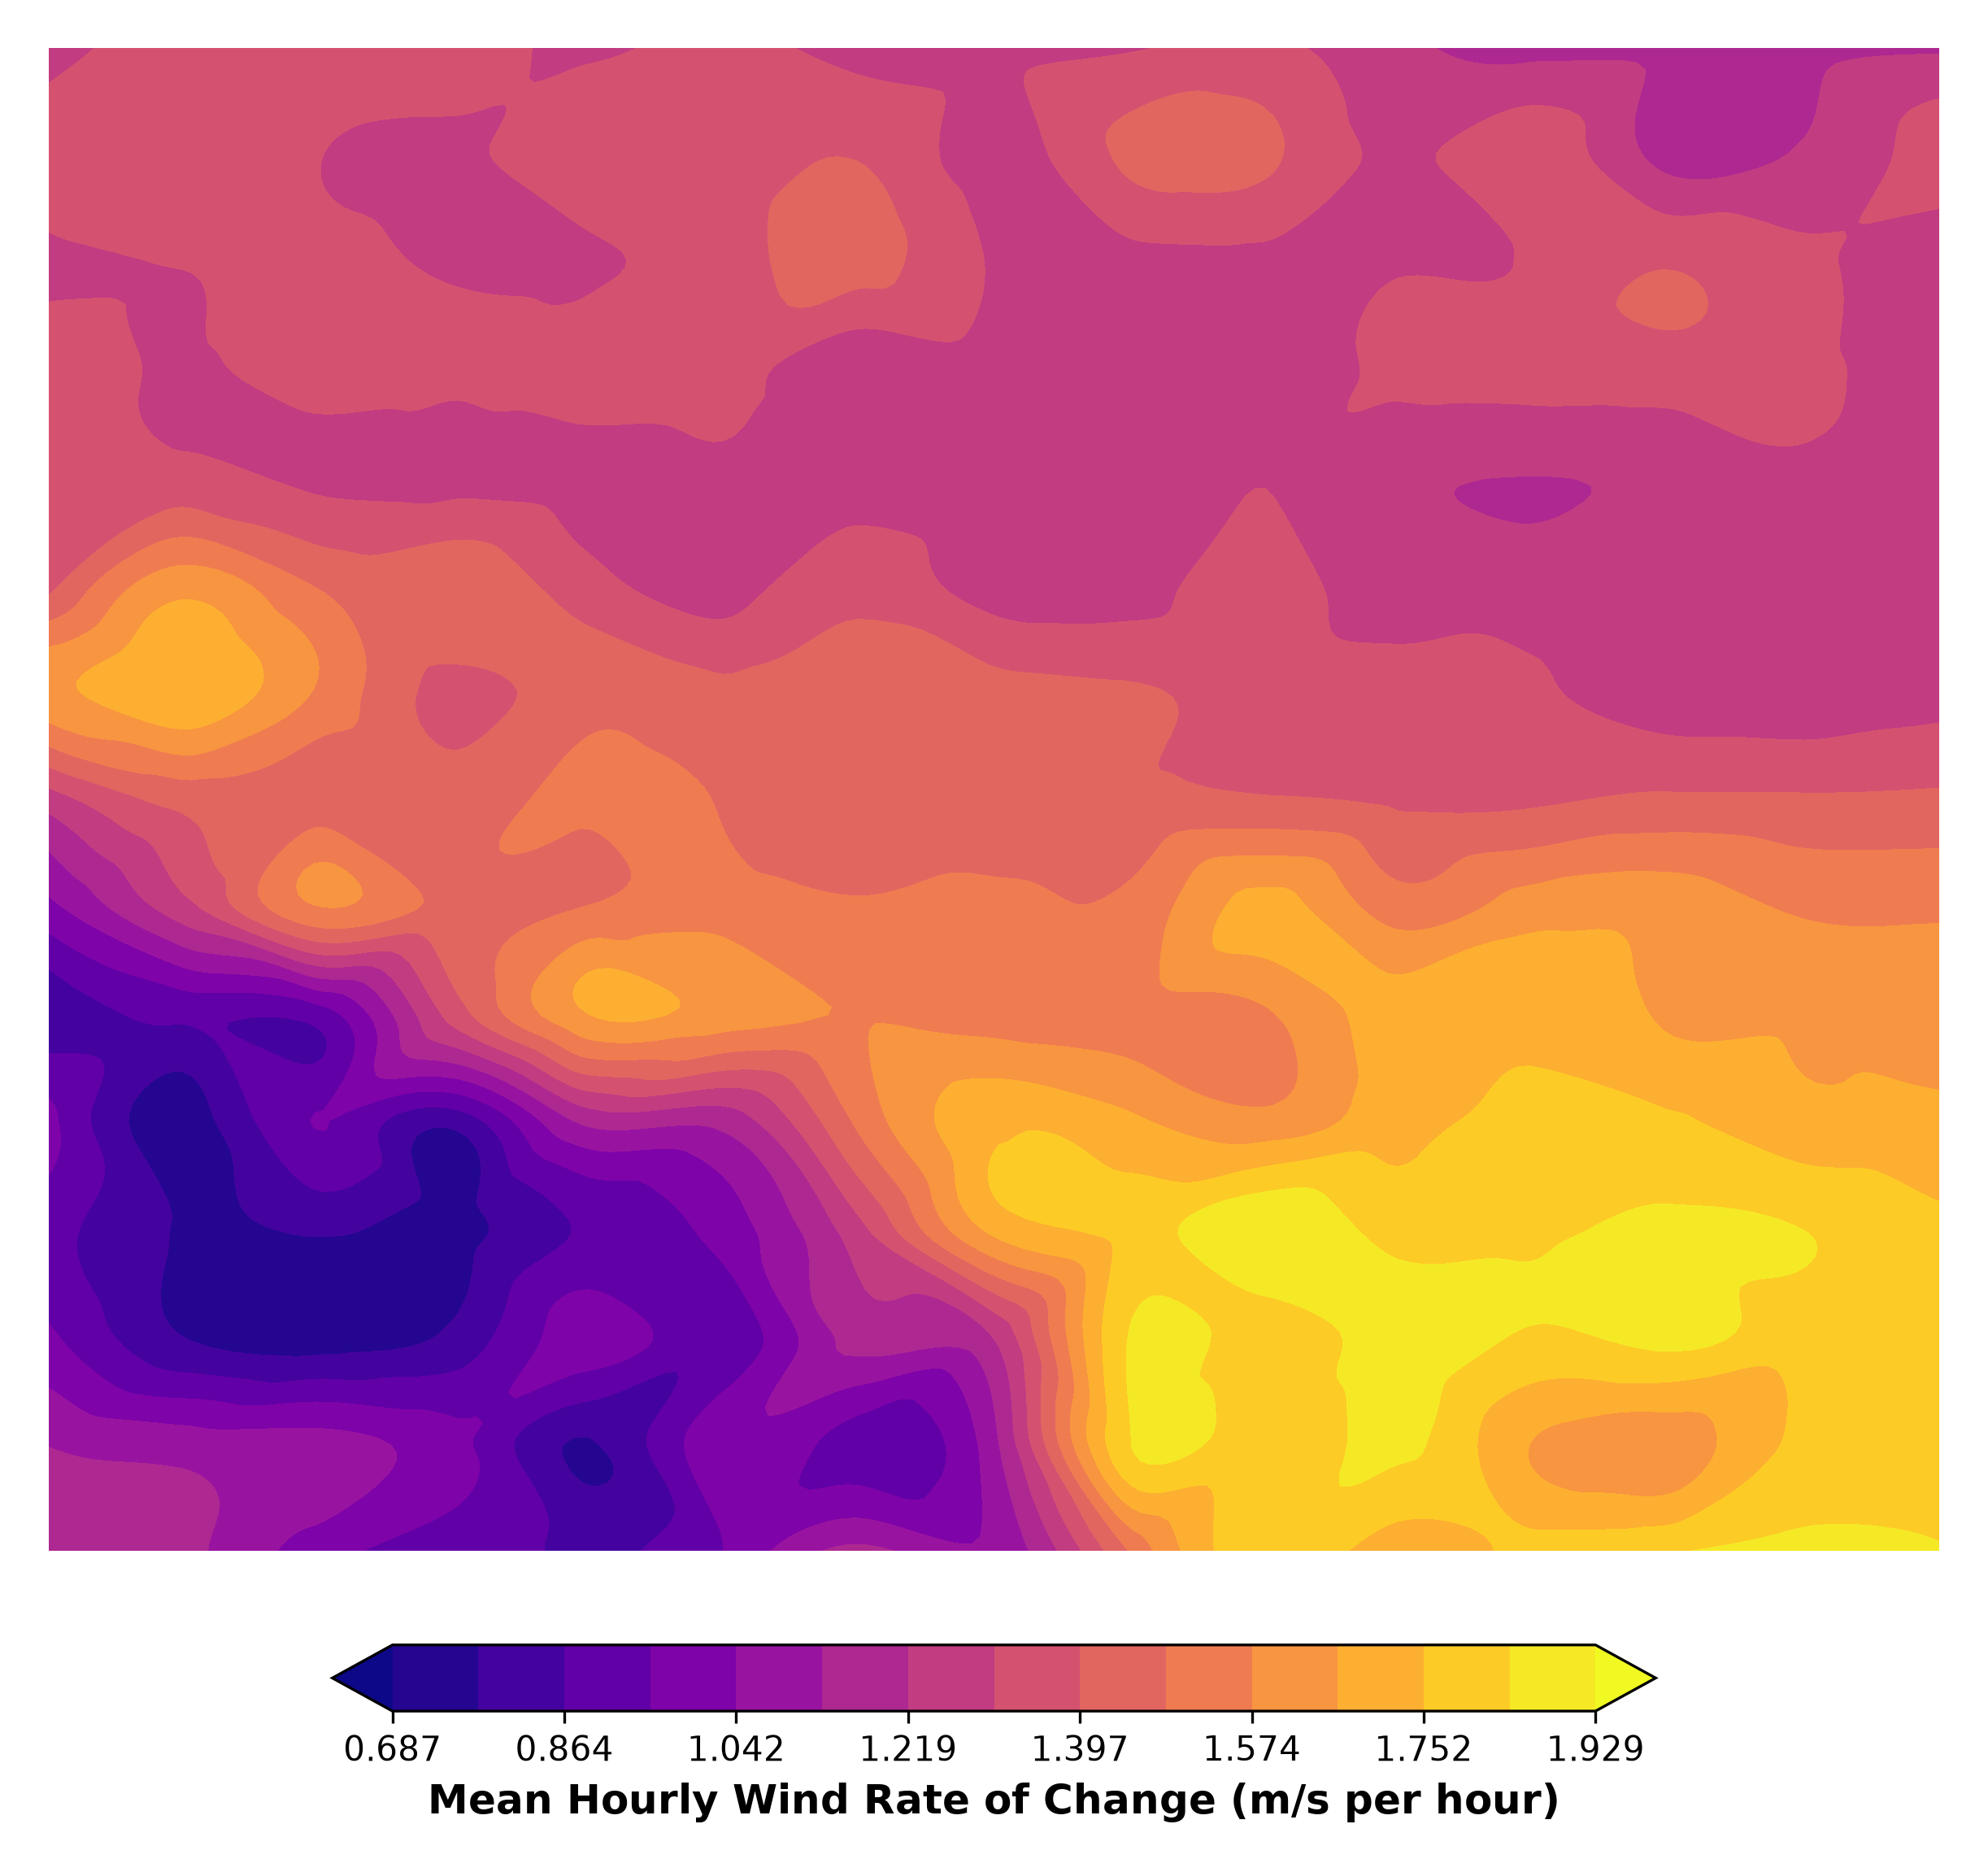

In [29]:
masterWeatherDF = masterWeatherDF.sort_values(["location","timestamp"])  # Ensure the DataFrame is available for further analysis or export
masterWeatherDF["wind_derivative"] = masterWeatherDF.groupby("location")["wind_speed_10m"].diff().abs()  # Calculate the derivative of wind speed for each location
siteChange = masterWeatherDF.groupby(["location", "latitude", "longitude"])["wind_derivative"].mean().reset_index()

points = siteChange[["latitude", "longitude"]].values
values = siteChange["wind_derivative"].values

# 4. Create a dense spatial grid for interpolation (200x200 mesh)
gridLat = np.linspace(49.5, 59.5, 200)
gridLong = np.linspace(-119.5, -110.5, 200)
GRIDLAT, GRIDLONG = np.meshgrid(gridLat, gridLong)

# Interpolate the derivative metric across the province
GRID_CHANGE = griddata(points, values, (GRIDLAT, GRIDLONG), method='cubic')

# 5. Render a Contour Plot for Temporal Change
fig, ax = plt.subplots(figsize=(10, 10))

# Define smooth contour levels using a perceptually uniform colormap ('plasma' or 'inferno')
levels = np.linspace(np.nanmin(GRID_CHANGE), np.nanmax(GRID_CHANGE), 15)
contour = ax.contourf(GRIDLONG, GRIDLAT, GRID_CHANGE, levels=levels, cmap='plasma', extend='both')

# Add an integrated colorbar legend
cbar = fig.colorbar(contour, ax=ax, orientation='horizontal', pad=0.05, shrink=0.7)
cbar.set_label('Mean Hourly Wind Rate of Change (m/s per hour)', fontsize=12, fontweight='bold', color='black')
cbar.ax.tick_params(labelsize=10)

ax.axis('off')

# Save transparent high-res overlay graphic
plt.savefig('wind_derivative_contour.png', bbox_inches='tight', pad_inches=0.2, transparent=True, dpi=300)
plt.close()

# 6. Overlay onto your Folium map
derivativeMap = folium.Map(location=[54.0, -115.0], zoom_start=6, tiles="openstreetmap")

folium.raster_layers.ImageOverlay(
    image='wind_derivative_contour.png',
    bounds=[[49.5, -119.5], [59.5, -110.5]], # Alberta bounds
    opacity=0.8,
    interactive=False,
).add_to(derivativeMap)

display(derivativeMap)

---
### **Finding the "Sweet Spot"**
To find ideal zones where high wind speeds overlap with low volatility (stable, consistent flow over time), we can combine both spatial grids into a Multi-Criteria Sweet-Spot Index.Mathematically, we normalize both the mean wind speed grid (GRIDWIND) and the volatility grid (GRID_CHANGE) to a $0\text{–}1$ scale, and compute a balance score:$$\text{Sweet-Spot Score} = \text{Normalized Wind Speed} - \text{Normalized Volatility}$$This rewards locations with strong winds while heavily penalizing erratic, highly turbulent weather patterns.

Top 5 Optimal Wind Farm Sweet-Spot Sites in Alberta:


,location,latitude,longitude,wind_speed_10m,wind_derivative,sweet_spot_score
84,Site_175,57.3571,-113.7143,11.776207,1.248093,0.331164
124,Site_210,58.7857,-110.5000,12.856512,1.361391,0.327728
103,Site_192,58.0714,-112.4286,12.335018,1.313686,0.323560
81,Site_172,57.3571,-115.6429,11.528199,1.235432,0.320820
122,Site_209,58.7857,-111.1429,11.238786,1.230502,0.300539



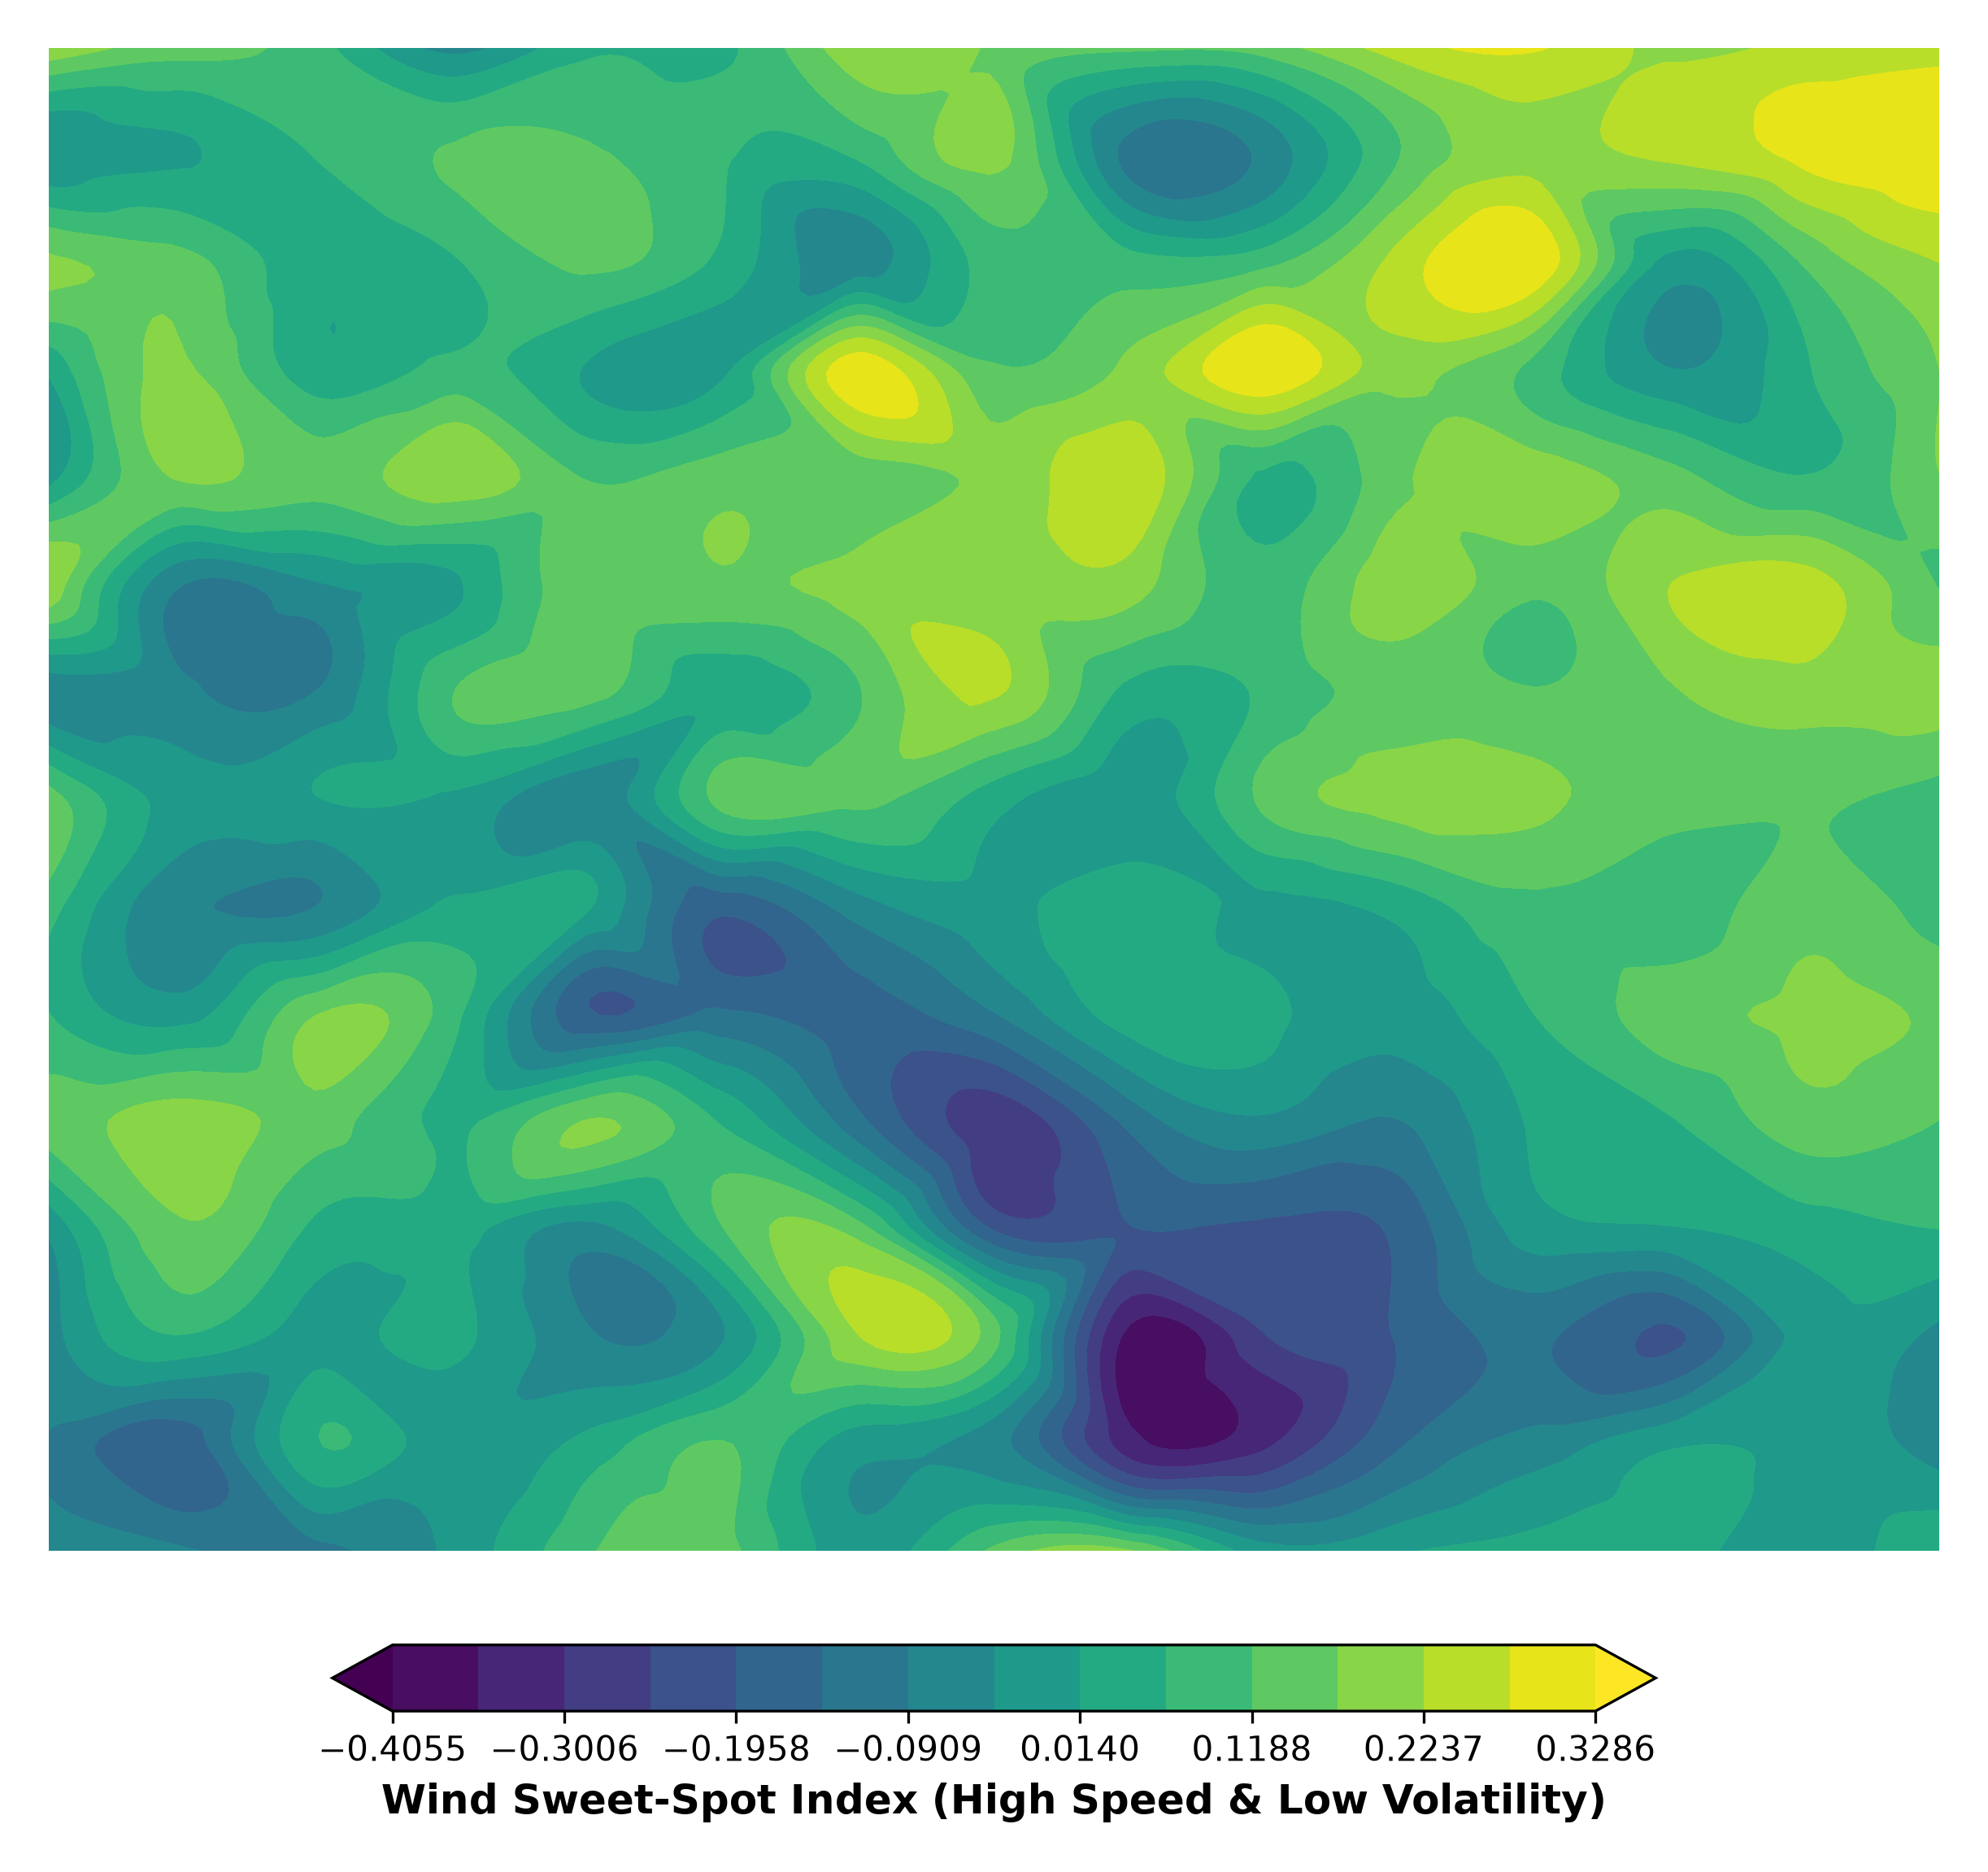

In [30]:
# 1. Compute site-level combined metrics
site_means = masterWeatherDF.groupby(["location", "latitude", "longitude"])["wind_speed_10m"].mean().reset_index()
site_changes = masterWeatherDF.groupby(["location"])["wind_derivative"].mean().reset_index()

site_combined = pd.merge(site_means, site_changes, on="location")

# Normalize metrics for scoring
s_min, s_max = site_combined["wind_speed_10m"].min(), site_combined["wind_speed_10m"].max()
d_min, d_max = site_combined["wind_derivative"].min(), site_combined["wind_derivative"].max()

norm_speed = (site_combined["wind_speed_10m"] - s_min) / (s_max - s_min + 1e-5)
norm_deriv = (site_combined["wind_derivative"] - d_min) / (d_max - d_min + 1e-5)

# Higher score = Strong winds + Low volatility (Stable & Fast)
site_combined["sweet_spot_score"] = norm_speed - norm_deriv

print("Top 5 Optimal Wind Farm Sweet-Spot Sites in Alberta:")
display(site_combined.sort_values(by="sweet_spot_score", ascending=False).head(5))

# 2. Compute the Grid-level Sweet-Spot Surface across the 200x200 mesh
norm_grid_wind = (GRIDWIND - np.nanmin(GRIDWIND)) / (np.nanmax(GRIDWIND) - np.nanmin(GRIDWIND) + 1e-5)
norm_grid_change = (GRID_CHANGE - np.nanmin(GRID_CHANGE)) / (np.nanmax(GRID_CHANGE) - np.nanmin(GRID_CHANGE) + 1e-5)

GRID_SWEETSPOT = norm_grid_wind - norm_grid_change

# 3. Render Contour Plot for the Sweet-Spot Index
fig, ax = plt.subplots(figsize=(10, 10))

levels = np.linspace(np.nanmin(GRID_SWEETSPOT), np.nanmax(GRID_SWEETSPOT), 15)
# Using 'viridis' where brighter/higher values represent prime locations
contour = ax.contourf(GRIDLONG, GRIDLAT, GRID_SWEETSPOT, levels=levels, cmap='viridis', extend='both')

# Add an integrated colorbar legend
cbar = fig.colorbar(contour, ax=ax, orientation='horizontal', pad=0.05, shrink=0.7)
cbar.set_label('Wind Sweet-Spot Index (High Speed & Low Volatility)', fontsize=12, fontweight='bold', color='black')
cbar.ax.tick_params(labelsize=10)

ax.axis('off')

# Save transparent high-res overlay graphic
plt.savefig('wind_sweetspot_contour.png', bbox_inches='tight', pad_inches=0.2, transparent=True, dpi=300)
plt.close()

# 4. Overlay onto a new Folium map
sweetSpotMap = folium.Map(location=[54.0, -115.0], zoom_start=6, tiles="openstreetmap")

folium.raster_layers.ImageOverlay(
    image='wind_sweetspot_contour.png',
    bounds=[[49.5, -119.5], [59.5, -110.5]], # Alberta bounds
    opacity=0.8,
    interactive=False,
).add_to(sweetSpotMap)

display(sweetSpotMap)